In [10]:
from langgraph.graph import StateGraph, START, END
from langchain_ollama import ChatOllama
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import StrOutputParser
from typing import TypedDict

In [11]:
class blog_state(TypedDict):
    outline : str
    topic : str
    blog : str
    

In [12]:
graph = StateGraph(blog_state)

In [13]:
llm = ChatOllama(model='gemma3:4b')

In [14]:
def outline(state : blog_state) -> blog_state:
    template = PromptTemplate(
        template = 'Give me just the outline or structure for the blog i am writing on {topic}. NOTE that only give me the outline or structure no other thing in output.',
        input_variables=['topic']
    )

    prompt = template.invoke({
        'topic' : state['topic']
    })

    response = llm.invoke(prompt)

    state['outline'] = response.content

    return state

In [15]:
def blog(state : blog_state) -> blog_state:
    template = PromptTemplate(
        template = 'Give me a blog on the topic - {topic} and using this outline - {outline}',
        input_variables=['topic', 'outline']
    )

    prompt = template.invoke({
        'topic' : state['topic'],
        'outline' : state['outline']
    })

    response = llm.invoke(prompt)

    state['blog'] = response.content

    return state

In [16]:
graph.add_node('outline', outline)

graph.add_node('blog', blog)

graph.add_edge(START, 'outline')
graph.add_edge('outline', 'blog')
graph.add_edge('blog', END)


workflow = graph.compile()

In [18]:
final_state = workflow.invoke({
    'topic' : 'Agentic AI'
})

In [19]:
final_state['blog']

"Okay, here's a blog post based on your outline, designed to be informative and engaging for a general audience interested in the emerging field of Agentic AI.\n\n---\n\n## Agentic AI: The Rise of Thinking Machines That Act\n\n**I. Introduction**\n\nA. **What is Agentic AI?** (Brief Definition) Agentic AI refers to a new paradigm in artificial intelligence where systems aren't just *analyzing* data or *predicting* outcomes, but actively *doing* things in the world. Think of it as AI that can not just understand a problem, but formulate a plan and execute it, adapting as it goes.  It's about building intelligent agents that can autonomously interact with their environment.\n\nB. **The Problem Agentic AI Solves** Traditionally, AI has often been limited to narrow applications.  Many AI systems require constant human intervention – someone to feed them data, tell them what to do, and interpret the results. Agentic AI aims to break free from this constraint by creating systems that can han

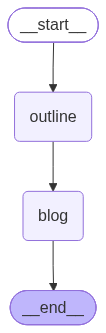

In [20]:
workflow